# Predicting Income from Census Data

The goal here is to predict whether or not a person makes more than $50,000 in a year using a random forest classifier.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, RandomForestRegressor
from sklearn import tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

In [3]:
# Names of the features, not already part of the csv
col_names = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
feature_cols = ['age', 'capital-gain', 'capital-loss', 'hours-per-week', 'sex', 'race']

df = pd.read_csv('./Data Files/adults.csv', header=None, names=col_names)
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
# Strip leading/trailing whitespaces from all string columns
for col in col_names:
  if type(df[col][0]) == str:
    df[col] = df[col].str.strip()
print("Percentage of adults who made more than $50,000: {:.2f}%".format(df.income.value_counts(normalize=True).loc['>50K'] * 100))

Percentage of adults who made more than $50,000: 24.08%


In [5]:
# Create features and target
y = np.where(df['income'] == ">50K", 1, 0)
X = pd.get_dummies(df[feature_cols], drop_first=True)

In [6]:
# Create training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    train_size = 0.8,
    random_state = 1
)

## Default Random Forest

The first model trained will be a default forest used as a baseline.

In [7]:
rfc = RandomForestClassifier()
rfc.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [8]:
print("The default model was {:.2f}% accurate.".format(rfc.score(x_test, y_test) * 100))

The default model was 81.96% accurate.


## Optimizing Depth

The next model will be created by trying 25 separate potential maximum depths, taking the highest accuracy model for evaluation.

In [9]:
# Accuracy on training/testing data for depths from 1-25
accuracy_train = []
accuracy_test = []
depths = range(1, 26)
for d in depths:
  rfc = RandomForestClassifier(max_depth=d)
  rfc.fit(x_train, y_train)
  acc_train = rfc.score(x_train, y_train)
  acc_test = rfc.score(x_test, y_test)
  accuracy_train.append(acc_train)
  accuracy_test.append(acc_test)

In [10]:
largest_accuracy = np.max(accuracy_test)
largest_accuracy_depth = np.argmax(accuracy_test)
print("The best model was {:.2f}% accurate with a depth of {}.".format(largest_accuracy * 100, largest_accuracy_depth))

The best model was 83.51% accurate with a depth of 12.


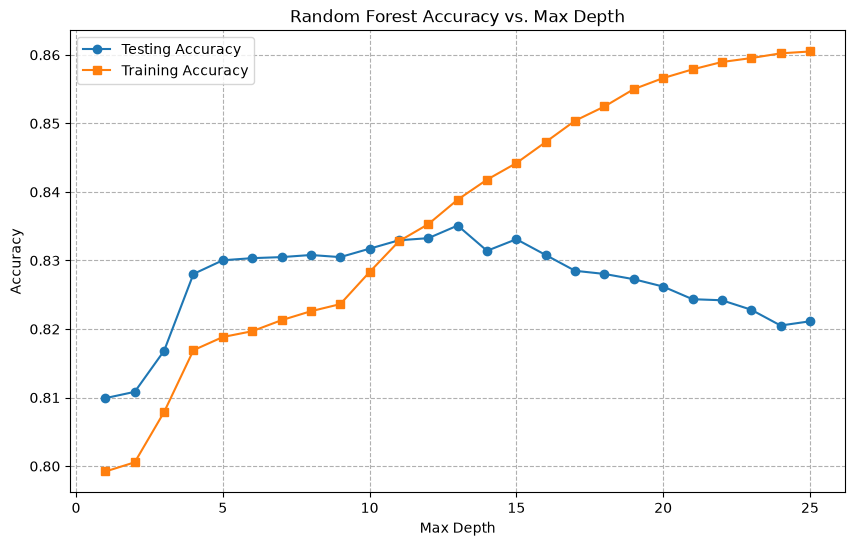

In [11]:
plt.figure(figsize=(10, 6))
plt.plot(depths, accuracy_test, label='Testing Accuracy', marker='o')
plt.plot(depths, accuracy_train, label='Training Accuracy', marker='s')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Random Forest Accuracy vs. Max Depth')
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

Pretty clear at what depth models begin to overfit: the training accuracy approximately matches the testing at 11 but continues to climb beyond that without having any effect on testing accuracy, which is steady from 4 to 18.

In [12]:
best_rfc = RandomForestClassifier(max_depth=largest_accuracy_depth, random_state=1)
best_rfc.fit(x_train, y_train)

feature_importances = pd.Series(rfc.feature_importances_, index=X.columns).sort_values(ascending=False)

display(feature_importances.head())

age               0.306299
capital-gain      0.295484
hours-per-week    0.192872
capital-loss      0.119564
sex_Male          0.062943
dtype: float64

Primary important categories include age, capital gain, hours per week, capital loss, and sex. All of these are in some way connected to earning power, so this makes sense. Older adults are later in their careers with more experience and earning power, capital gain and loss will have very direct impacts on income, generally more hours worked leads to more income, and men tend to make more than women.

## Adding Education

The education information isn't terribly helpful because it is labeled numerically, which doesn't provide practical information about whether someone has a diploma or degree. This information will be binned and re-labeled to see if more insight can be gained.

In [13]:
# Grouping various education levels into bins
df['education-bin'] = pd.cut(
    df['education-num'],
    [0, 9, 13, 16],
    labels = ['HS or less', 'College to Bachelors', 'Masters or more']
)

In [14]:
# Create dummy values which models can interpret
feature_cols.append('education-bin')
X = pd.get_dummies(df[feature_cols], drop_first=True)
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    train_size = 0.8,
    random_state = 1
)

In [15]:
# Try many maximum depths to find most accurate tree size
accuracy_train = []
accuracy_test = []
for d in depths:
  rfc_md = RandomForestClassifier(max_depth=d, random_state=99)
  rfc_md.fit(x_train, y_train)
  acc_train = rfc_md.score(x_train, y_train)
  acc_test = rfc_md.score(x_test, y_test)
  accuracy_train.append(acc_train)
  accuracy_test.append(acc_test)

In [16]:
largest_accuracy = np.max(accuracy_test)
largest_accuracy_depth = np.argmax(accuracy_test)
print("The best model was {:.2f}% accurate with a depth of {}.".format(largest_accuracy * 100, largest_accuracy_depth))

The best model was 85.06% accurate with a depth of 15.


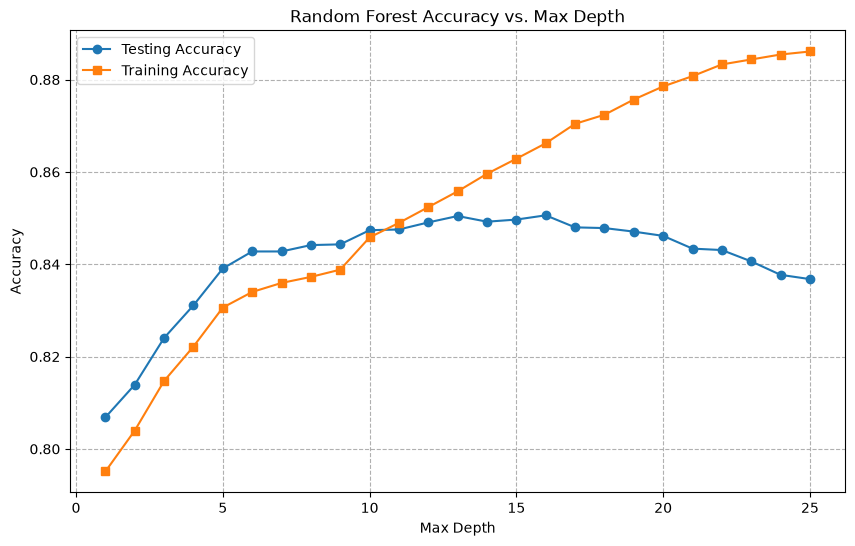

In [17]:
plt.figure(figsize=(10, 6))
plt.plot(depths, accuracy_test, label='Testing Accuracy', marker='o')
plt.plot(depths, accuracy_train, label='Training Accuracy', marker='s')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Random Forest Accuracy vs. Max Depth')
plt.legend()
plt.grid(True, linestyle='--')
plt.show()

In [18]:
best_rfc = RandomForestClassifier(max_depth=largest_accuracy_depth, random_state=1)
best_rfc.fit(x_train, y_train)

# Map importances to the feature (column) names and sort them descending
feature_importances = pd.Series(best_rfc.feature_importances_, index=X.columns).sort_values(ascending=False)

# Display the most important features
display(feature_importances.head())

capital-gain                     0.290732
age                              0.230220
hours-per-week                   0.134932
capital-loss                     0.105107
education-bin_Masters or more    0.101400
dtype: float64

The new education category is quite important, and actually knocks sex out of the top 5 most important features. According to the model, it's more important to be educated than to be a man.